# 03 · Forecast, model comparison and a real-world check

*Demonstration project using public data (Olist). Not affiliated with any employer.*

**Question:** what revenue should we plan for **H2 2018** (Jul–Dec 2018) if nothing changes?
H2 2018 = Jul–Aug actuals (already in the data) + a Sep–Dec forecast. Built by `python -m src.forecast`.

**Eight candidate models**, all specified before any check against later months:

| Model | Uses |
|---|---|
| Last month repeated, 3-month average, random walk with drift, AutoETS, AutoTheta | revenue only |
| Driver-based | customers (AutoETS) x orders per customer x AOV (3-month averages), per market |
| Regression | revenue k months ahead ~ revenue now + customer momentum (last 3 months), per market |
| Prophet | daily revenue, weekly + yearly seasonality, Black Friday as a holiday |

- **Backtest:** rolling origin, 4 starting points, each forecasting as many months ahead as the plan needs.
- **Selection:** lowest average WAPE across the total and the 5 markets.
- **Real-world check:** rerun everything as if it were the end of June 2018 and score on the real Jul–Aug.

In [1]:
import json, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from src import config as cfg
from src.forecast import LABELS

P = cfg.PROCESSED_DIR
cv = pd.read_csv(P / "backtest_predictions.csv")
scores = pd.read_csv(P / "backtest_scores.csv")
fc = pd.read_csv(P / "forecast.csv")
summ = json.loads((P / "forecast_summary.json").read_text())
chk = pd.read_csv(P / "forecast_check.csv").set_index("model")
paths = pd.read_csv(P / "forecast_check_paths.csv")
hist = pd.read_csv(P / "monthly_total.csv")
hist = hist[hist["in_model_window"]]
for d in (cv, fc, hist, paths):
    d["ds"] = pd.PeriodIndex(d["month"], freq="M").to_timestamp()
BEST = summ["selected_model"]

SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK2, MUTED, GRID, AXIS, SURF = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "axes.edgecolor": AXIS,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.grid.axis": "y",
    "grid.color": GRID, "grid.linewidth": 0.8, "axes.labelcolor": INK2, "xtick.color": MUTED,
    "ytick.color": MUTED, "text.color": INK, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "lines.linewidth": 2, "font.size": 10, "legend.frameon": False,
    "font.family": ["Segoe UI", "DejaVu Sans"],
})
IMG = cfg.IMAGES_DIR
brl_m = mtick.FuncFormatter(lambda v, _: f"R$ {v/1e6:.1f}M")
pct = mtick.PercentFormatter(1.0, decimals=0)
SHORT = {"Naive": "Last month repeated", "WindowAverage": "3-month average", "RWD": "Random walk + drift",
         "AutoETS": "AutoETS", "AutoTheta": "AutoTheta", "Drivers": "Driver-based", "Prophet": "Prophet",
         "LagRegression": "Customer-momentum regression"}

## 1. Backtest scores (data up to Aug 2018)

WAPE = total absolute error / total actual revenue. Bias = total error / total actual: negative means the
model forecast too low.

In [2]:
w = scores.pivot(index="model", columns="unique_id", values="wape")[cfg.MARKETS + ["Total"]]
w["average"] = w.mean(axis=1)
b = scores[scores["unique_id"] == "Total"].set_index("model")["bias"]
tab = pd.concat([(w * 100).round(1), (b * 100).round(1).rename("Total bias")], axis=1).sort_values("average")
tab.index = tab.index.map(SHORT)
print(f"Backtest: 4 origins ({cv['cutoff'].min()} to {cv['cutoff'].max()}), {cfg.FORECAST_H} months ahead each")
tab

Backtest: 4 origins (2018-01 to 2018-04), 4 months ahead each


,SP,RJ,MG,South,Rest of Brazil,Total,average,Total bias
model,,,,,,,,
3-month average,13.2,9.8,7.6,14.7,8.6,8.5,10.4,-4.1
Last month repeated,12.7,9.7,8.1,17.4,8.9,8.6,10.9,0.0
Customer-momentum regression,23.6,13.0,22.6,20.3,8.7,11.2,16.5,6.9
Random walk + drift,17.7,20.7,23.8,25.4,16.5,17.9,20.3,16.4
Driver-based,14.9,27.6,28.2,26.7,14.0,18.1,21.6,18.1
AutoETS,14.5,19.7,30.8,22.3,21.7,22.9,22.0,22.9
AutoTheta,12.7,31.0,30.4,21.8,18.5,18.4,22.1,18.4
Prophet,75.3,201.6,117.5,57.5,57.5,75.0,97.4,58.2


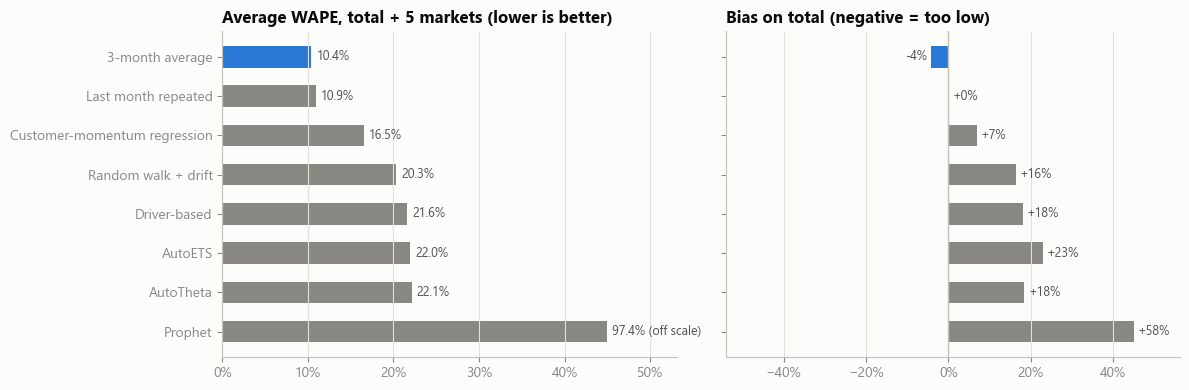

In [3]:
order = w["average"].sort_values().index
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
y = range(len(order))[::-1]
avg = w.loc[order, "average"]
cap = 0.45  # Prophet's error is far off the scale: cut the bar and label it
axes[0].barh(list(y), avg.clip(upper=cap), height=0.55, color=[SERIES[0] if m == BEST else MUTED for m in order])
axes[0].set_yticks(list(y), [SHORT[m] for m in order]); axes[0].xaxis.set_major_formatter(pct)
axes[0].set_xlim(0, cap * 1.18)
axes[0].set_title("Average WAPE, total + 5 markets (lower is better)")
for yi, m in zip(y, order):
    v = avg[m]
    axes[0].text(min(v, cap) + 0.006, yi, f"{v:.1%}" + (" (off scale)" if v > cap else ""), va="center",
                 color=INK2, fontsize=9)
bb = b.loc[order].clip(-cap, cap)
axes[1].barh(list(y), bb, height=0.55, color=[SERIES[0] if m == BEST else MUTED for m in order])
axes[1].axvline(0, color=AXIS, lw=1)
axes[1].set_yticks(list(y), [""] * len(order)); axes[1].xaxis.set_major_formatter(pct)
axes[1].set_title("Bias on total (negative = too low)")
for yi, m in zip(y, order):
    v = b.loc[m]; vv = max(min(v, cap), -cap)
    axes[1].text(vv + (0.01 if v >= 0 else -0.01), yi, f"{v:+.0%}", va="center",
                 ha="left" if v >= 0 else "right", color=INK2, fontsize=9)
axes[1].set_xlim(-cap * 1.2, cap * 1.25)
for ax in axes: ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
fig.tight_layout(); fig.savefig(IMG / "03_backtest_scores.png", dpi=150); plt.show()

In [4]:
t = w["Total"].sort_values()
print(f"Selected: {SHORT[BEST]} ({w.loc[BEST, 'average']:.1%} average WAPE). Runner-up: {SHORT[w['average'].sort_values().index[1]]}.")
trend = ["RWD", "AutoETS", "AutoTheta"]
print(f"The trend models over-forecast by {b[trend].min():+.0%} to {b[trend].max():+.0%}: they carry 2017's growth into 2018.")
print(f"The richer models did not help: driver-based {w.loc['Drivers','average']:.1%}, customer-momentum regression "
      f"{w.loc['LagRegression','average']:.1%}, Prophet {w.loc['Prophet','average']:.0%}.")
print("Prophet's forced yearly seasonality is unstable when trained on 13-16 months; it needs 2+ years of history.")

Selected: 3-month average (10.4% average WAPE). Runner-up: Last month repeated.
The trend models over-forecast by +16% to +23%: they carry 2017's growth into 2018.
The richer models did not help: driver-based 21.6%, customer-momentum regression 16.5%, Prophet 97%.
Prophet's forced yearly seasonality is unstable when trained on 13-16 months; it needs 2+ years of history.


## 2. What the backtest looked like

Each panel is one forecast origin: the 3-month average against one trend model (AutoETS) and the actuals.

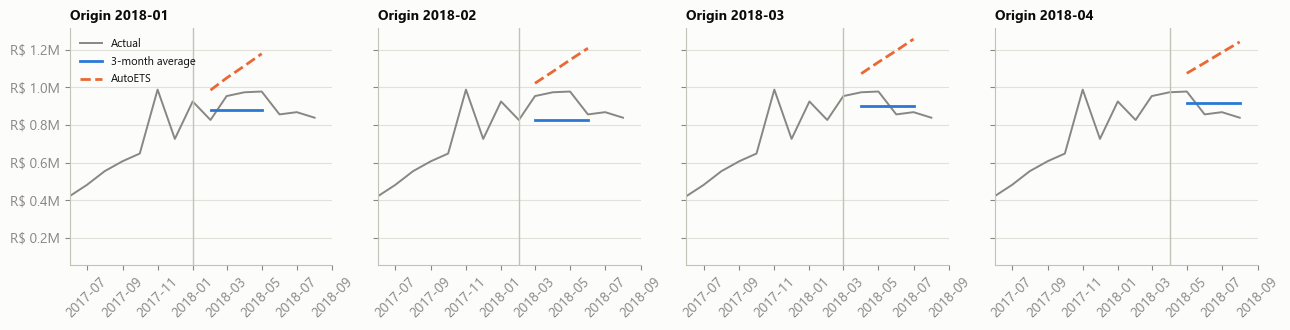

In [5]:
tot = cv[cv["unique_id"] == "Total"]
cuts = sorted(tot["cutoff"].unique())
fig, axes = plt.subplots(1, len(cuts), figsize=(13, 3.4), sharey=True)
for ax, c in zip(axes, cuts):
    g = tot[tot["cutoff"] == c]
    ax.plot(hist["ds"], hist["revenue"], color=MUTED, lw=1.4, label="Actual")
    ax.plot(g["ds"], g["WindowAverage"], color=SERIES[0], label="3-month average")
    ax.plot(g["ds"], g["AutoETS"], color=SERIES[1], ls="--", label="AutoETS")
    ax.axvline(pd.Period(c, "M").to_timestamp(), color=AXIS, lw=1)
    ax.set_title(f"Origin {c}", fontsize=10); ax.yaxis.set_major_formatter(brl_m)
    ax.set_xlim(pd.Timestamp("2017-06-01"), pd.Timestamp("2018-09-01")); ax.tick_params(axis="x", labelrotation=45)
axes[0].legend(loc="upper left", fontsize=8)
fig.tight_layout(); fig.savefig(IMG / "03_backtest_paths.png", dpi=150); plt.show()

## 3. Would it have worked? Planning from June 2018

Rerun the whole comparison as if it were the end of June 2018, then score against what really happened in
Jul–Aug 2018. The model designs were fixed before this check and were not tuned afterwards.

In [6]:
c = chk.copy()
c.index = c.index.map(SHORT)
c = c[["backtest_avg_wape", "check_total_error", "check_avg_wape"]].rename(columns={
    "backtest_avg_wape": "Backtest WAPE, data to Jun (%)", "check_total_error": "Error on real Jul-Aug, total (%)",
    "check_avg_wape": "WAPE on Jul-Aug, total + markets (%)"}) * 100
c.round(1).sort_values("Backtest WAPE, data to Jun (%)")

,"Backtest WAPE, data to Jun (%)","Error on real Jul-Aug, total (%)","WAPE on Jul-Aug, total + markets (%)"
model,,,
AutoTheta,17.8,28.7,28.8
Last month repeated,22.7,0.3,9.4
Random walk + drift,22.9,8.0,14.5
3-month average,23.6,9.7,15.9
AutoETS,26.7,15.7,29.1
Driver-based,29.9,23.5,30.7
Customer-momentum regression,35.0,6.5,14.8
Prophet,154.1,-3.4,14.1


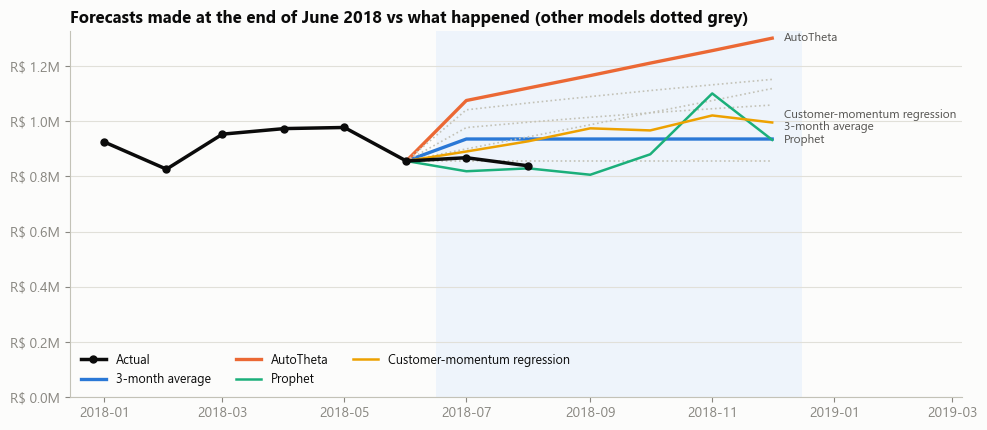

In June the backtest would have picked AutoTheta: Jul-Aug forecast +29% too high.
3-month average: +10%; best on the check: Last month repeated (+0.3%, partly luck: June happened to match Jul-Aug).


In [7]:
picked = summ["check"]["selected_by_backtest"]
h18 = hist[hist["month"] >= "2018-01"]
fig, ax = plt.subplots(figsize=(10, 4.4))
ax.axvspan(pd.Timestamp(cfg.CHECK_END) + pd.offsets.MonthBegin(1) - pd.Timedelta(days=15),
           paths["ds"].max() + pd.Timedelta(days=15), color="#eef4fb", lw=0, zorder=0)
ax.plot(h18["ds"], h18["revenue"], color=INK, marker="o", ms=5, lw=2.5, label="Actual", zorder=5)
june = hist.set_index("month").loc[cfg.CHECK_END, "revenue"]
start = pd.Period(cfg.CHECK_END, "M").to_timestamp()
style = {picked: (SERIES[1], "-", 2.4), "WindowAverage": (SERIES[0], "-", 2.4), "Prophet": (SERIES[2], "-", 1.8),
         "LagRegression": (SERIES[3], "-", 1.8)}
ends = {}
for m in [k for k in paths.columns if k not in ("month", "ds", "actual")]:
    col, ls, lw = style.get(m, ("#c3c2b7", ":", 1.2))
    x = [start] + list(paths["ds"]); y = [june] + list(paths[m])
    ax.plot(x, y, color=col, ls=ls, lw=lw, label=SHORT[m] if m in style else None)
    if m in style:
        ends[m] = y[-1]
# end labels, spaced so they never overlap
prev = None
for m, yv in sorted(ends.items(), key=lambda kv: kv[1]):
    yv = yv if prev is None else max(yv, prev + 45000)
    ax.text(paths["ds"].iloc[-1] + pd.Timedelta(days=6), yv, SHORT[m], color=INK2, fontsize=8.5, va="center")
    prev = yv
ax.yaxis.set_major_formatter(brl_m); ax.set_ylim(bottom=0)
ax.set_xlim(right=paths["ds"].max() + pd.Timedelta(days=95))
ax.set_title("Forecasts made at the end of June 2018 vs what happened (other models dotted grey)")
ax.legend(loc="lower left", fontsize=9, ncol=3)
fig.tight_layout(); fig.savefig(IMG / "03_forecast_check.png", dpi=150); plt.show()
print(f"In June the backtest would have picked {SHORT[picked]}: Jul-Aug forecast {chk.loc[picked, 'check_total_error']:+.0%} too high.")
print(f"3-month average: {chk.loc['WindowAverage', 'check_total_error']:+.0%}; best on the check: "
      f"{SHORT[summ['check']['best_on_check']]} ({chk.loc[summ['check']['best_on_check'], 'check_total_error']:+.1%}, partly luck: "
      "June happened to match Jul-Aug).")

## 4. The H2 2018 plan: Jul–Aug actual + Sep–Dec forecast

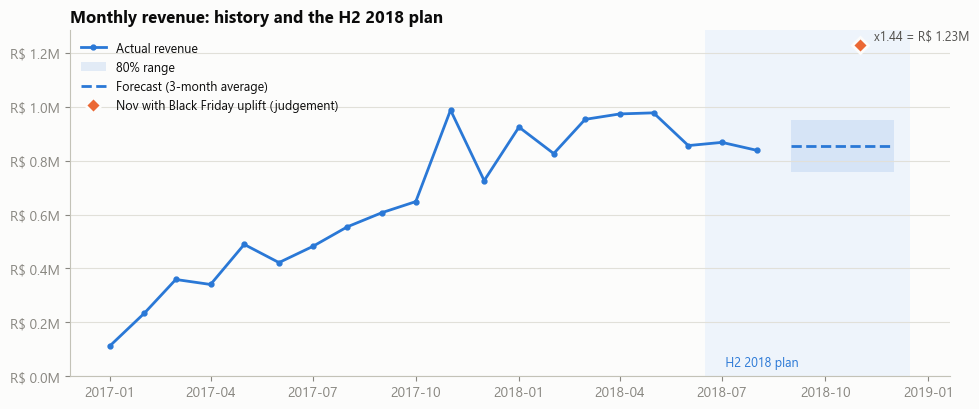

In [8]:
ft = fc[fc["unique_id"] == "Total"]
act = hist[hist["month"].isin(cfg.ACTUAL_MONTHS)]
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.axvspan(pd.Timestamp(cfg.PLAN_START + "-01") - pd.Timedelta(days=15), ft["ds"].max() + pd.Timedelta(days=15),
           color="#eef4fb", lw=0, zorder=0)
ax.text(pd.Timestamp(cfg.PLAN_START + "-01"), 0.03, f" {cfg.PLAN_NAME} plan", transform=ax.get_xaxis_transform(),
        color=SERIES[0], fontsize=9)
ax.plot(hist["ds"], hist["revenue"], color=SERIES[0], marker="o", ms=3.5, label="Actual revenue")
ax.fill_between(ft["ds"], ft["lo80"], ft["hi80"], color=SERIES[0], alpha=0.12, lw=0, label="80% range")
ax.plot(ft["ds"], ft["forecast"], color=SERIES[0], ls="--", label="Forecast (3-month average)")
nov = ft[ft["ds"].dt.month == cfg.BLACK_FRIDAY_MONTH]
ax.plot(nov["ds"], nov["forecast_bf"], marker="D", ms=8, color=SERIES[1], ls="none",
        markeredgecolor=SURF, markeredgewidth=2, label="Nov with Black Friday uplift (judgement)")
ax.annotate(f"x{summ['black_friday_uplift']:.2f} = R$ {nov['forecast_bf'].iloc[0]/1e6:.2f}M",
            (nov["ds"].iloc[0], nov["forecast_bf"].iloc[0]), xytext=(10, 4), textcoords="offset points",
            color=INK2, fontsize=9)
ax.yaxis.set_major_formatter(brl_m); ax.set_ylim(bottom=0)
ax.set_title(f"Monthly revenue: history and the {cfg.PLAN_NAME} plan"); ax.legend(loc="upper left", fontsize=9)
fig.tight_layout(); fig.savefig(IMG / "03_forecast.png", dpi=150); plt.show()

In [9]:
f = fc.copy()
ac = pd.read_csv(P / "monthly_market.csv")
ac = ac[ac["month"].isin(cfg.ACTUAL_MONTHS)].groupby("market")["revenue"].sum()
ac["Total"] = ac.sum()
k = f.groupby("unique_id")[["forecast", "lo80", "hi80", "forecast_bf"]].sum().loc[cfg.MARKETS + ["Total"]]
out = pd.DataFrame({
    f"{cfg.ACTUAL_LABEL} actual": ac.loc[k.index],
    f"{cfg.FORECAST_LABEL} forecast incl. Black Friday": k["forecast_bf"],
    f"{cfg.PLAN_NAME} plan": ac.loc[k.index] + k["forecast_bf"],
    "low 80% (forecast months)": k["lo80"], "high 80% (forecast months)": k["hi80"],
})
print("R$M. Market ranges do not add up to the total range.")
(out / 1e6).round(2)

R$M. Market ranges do not add up to the total range.


,Jul–Aug 2018 actual,Sep–Dec 2018 forecast incl. Black Friday,H2 2018 plan,low 80% (forecast months),high 80% (forecast months)
unique_id,,,,,
SP,0.71,1.55,2.26,1.11,1.69
RJ,0.19,0.43,0.62,0.34,0.44
MG,0.19,0.43,0.62,0.35,0.43
South,0.23,0.51,0.74,0.36,0.57
Rest of Brazil,0.39,0.86,1.25,0.64,0.91
Total,1.71,3.79,5.50,3.04,3.80


## 5. What this means for the plan

In [10]:
t = fc[fc["unique_id"] == "Total"]
prev = hist[hist["month"].between(*cfg.PREV_HALF)]["revenue"].sum()
plan = hist[hist["month"].isin(cfg.ACTUAL_MONTHS)]["revenue"].sum() + summ["forecast_total_bf"]
print(f"- {cfg.PLAN_NAME}: R$ {plan/1e6:.2f}M = {cfg.ACTUAL_LABEL} actual + {cfg.FORECAST_LABEL} forecast "
      f"(R$ {t['forecast'].iloc[0]/1e3:.0f}k a month, plus Black Friday). {cfg.PREV_HALF_NAME} actual: R$ {prev/1e6:.2f}M.")
print(f"- The forecast is flat by design: of eight models, the 3-month average was most accurate, and planning from "
      f"June the backtest's favourite over-forecast by {chk.loc[summ['check']['selected_by_backtest'], 'check_total_error']:+.0%}.")
print(f"- Black Friday x{summ['black_friday_uplift']:.2f} comes from a single November (2017): a planning assumption "
      "to confirm with the business. Growth has to come from explicit scenarios (notebook 04).")

- H2 2018: R$ 5.50M = Jul–Aug 2018 actual + Sep–Dec 2018 forecast (R$ 854k a month, plus Black Friday). H1 2018 actual: R$ 5.51M.
- The forecast is flat by design: of eight models, the 3-month average was most accurate, and planning from June the backtest's favourite over-forecast by +29%.
- Black Friday x1.44 comes from a single November (2017): a planning assumption to confirm with the business. Growth has to come from explicit scenarios (notebook 04).
